In [13]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)
num_schools = 500

# 1. Generate Raw Categorical & Numerical Data
regions_messy = [' littoral ', 'South-West', 'CENTRE', '  Far North', 'west', ' Littoral']
school_types = ['Government', 'Mission', 'Private']
zones = ['Urban', 'Rural']

data = {
    'School_ID': [f"CMR_{i:04d}" for i in range(1, num_schools + 1)],

    'Region': np.random.choice(regions_messy, num_schools),

    'School_Type': np.random.choice(school_types, num_schools, p=[0.5, 0.2, 0.3]),

    'Zone': np.random.choice(zones, num_schools, p=[0.6, 0.4]),

    'Total_Students': np.random.randint(150, 2500, num_schools),

    'Math_Teachers': np.random.randint(1, 10, num_schools),

    'CS_Teachers': np.random.randint(0, 5, num_schools),

    'Pct_DIPES_Teachers': np.round(np.random.uniform(10.0, 95.0, num_schools), 1),

    'Annual_STEM_Budget_FCFA': np.random.randint(500000, 15000000, num_schools)
}

# Create DataFrame
df = pd.DataFrame(data)
print("Step 1 Complete: Base raw data generated.")
df.head(10)

Step 1 Complete: Base raw data generated.


,School_ID,Region,School_Type,Zone,Total_Students,Math_Teachers,CS_Teachers,Pct_DIPES_Teachers,Annual_STEM_Budget_FCFA
0,CMR_0001,Far North,Government,Urban,1898,4,4,43.0,11470761
1,CMR_0002,west,Government,Rural,308,5,0,63.8,9741937
2,CMR_0003,CENTRE,Government,Urban,2127,8,3,69.8,2230085
3,CMR_0004,west,Mission,Urban,1106,4,2,10.4,2526110
4,CMR_0005,west,Mission,Urban,2221,4,2,24.2,11973170
5,CMR_0006,South-West,Government,Rural,553,3,1,70.6,6141379
6,CMR_0007,CENTRE,Government,Urban,665,7,4,66.6,13483738
7,CMR_0008,CENTRE,Mission,Urban,1537,3,4,92.1,9325150
8,CMR_0009,CENTRE,Mission,Urban,1105,3,4,74.7,6019948
9,CMR_0010,west,Private,Rural,2349,5,3,90.8,7428887


In [14]:

# PART A: DATA CLEANING

def standardize_region(region_str):
    cleaned = region_str.strip().title()
    return cleaned.replace("South-West", "South West")

df['Region'] = df['Region'].apply(standardize_region)


# PART B: FEATURE ENGINEERING

df['Total_STEM_Teachers'] = df['Math_Teachers'] + df['CS_Teachers']

df['STEM_Student_Teacher_Ratio'] = df.apply(
    lambda row: round(row['Total_Students'] / row['Total_STEM_Teachers'], 1) 
    if row['Total_STEM_Teachers'] > 0 else np.nan, axis=1
)

df['Pedagogical_Impact_Score'] = df.apply(
    lambda row: round((row['Pct_DIPES_Teachers'] * 10) / row['STEM_Student_Teacher_Ratio'], 2)
    if row['STEM_Student_Teacher_Ratio'] > 0 else 0, axis=1
)


# PART C: CALCULATE REALISTIC GCE PASS RATE

base_rate = 40.0
pis_contribution = df['Pedagogical_Impact_Score'] * 2.5
budget_contribution = (df['Annual_STEM_Budget_FCFA'] / 15_000_000) * 10.0
type_bonus = df['School_Type'].map({'Mission': 6.0, 'Private': 3.0, 'Government': 0.0})
random_noise = np.random.normal(loc=0, scale=3.5, size=len(df))

# Calculate and clip the final rate
df['GCE_AL_Pass_Rate'] = np.clip(
    base_rate + pis_contribution + budget_contribution + type_bonus + random_noise, 
    15.0, 100.0
).round(2)

# Display the final, logically sound table
print("=== CLEANED, ENGINEERED & LOGICALLY ALIGNED DATAFRAME ===")
df[['School_ID', 'Region', 'Zone', 'STEM_Student_Teacher_Ratio', 'Pedagogical_Impact_Score', 'GCE_AL_Pass_Rate']].head(10)

=== CLEANED, ENGINEERED & LOGICALLY ALIGNED DATAFRAME ===


,School_ID,Region,Zone,STEM_Student_Teacher_Ratio,Pedagogical_Impact_Score,GCE_AL_Pass_Rate
0,CMR_0001,Far North,Urban,237.2,1.81,56.84
1,CMR_0002,West,Rural,61.6,10.36,74.60
2,CMR_0003,Centre,Urban,193.4,3.61,54.26
3,CMR_0004,West,Urban,184.3,0.56,56.15
4,CMR_0005,West,Urban,370.2,0.65,58.99
5,CMR_0006,South West,Rural,138.2,5.11,58.03
6,CMR_0007,Centre,Urban,60.5,11.01,82.23
7,CMR_0008,Centre,Urban,219.6,4.19,68.83
8,CMR_0009,Centre,Urban,157.9,4.73,68.03
9,CMR_0010,West,Rural,293.6,3.09,53.96


In [17]:

# PART D: STATISTICAL ANALYSIS & REGIONAL INSIGHTS


# 1. Regional Breakdown: Evaluating the National Spread
regional_summary = df.groupby('Region').agg(
    Total_Schools=('School_ID', 'count'),
    Avg_Pass_Rate=('GCE_AL_Pass_Rate', 'mean'),
    Avg_PIS=('Pedagogical_Impact_Score', 'mean'),
    Avg_Student_Teacher_Ratio=('STEM_Student_Teacher_Ratio', 'mean')
).round(2).sort_values(by='Avg_Pass_Rate', ascending=False)

print("--- REGIONAL EDUCATIONAL SUMMARY ---")
print(regional_summary)

# 2. Urban vs. Rural Disparity: Evaluating the Resource Gap

zone_summary = df.groupby(['Zone', 'School_Type']).agg(
    Total_Schools=('School_ID', 'count'),
    Avg_Pass_Rate=('GCE_AL_Pass_Rate', 'mean'),
    Avg_Budget_FCFA=('Annual_STEM_Budget_FCFA', 'mean'),
    Avg_PIS=('Pedagogical_Impact_Score', 'mean')
).round(2).sort_values(by=['Zone', 'Avg_Pass_Rate'], ascending=[True, False])

print("--- URBAN VS RURAL SECTOR DISPARITY ---")
print(zone_summary)



--- REGIONAL EDUCATIONAL SUMMARY ---
            Total_Schools  Avg_Pass_Rate  Avg_PIS  Avg_Student_Teacher_Ratio
Region                                                                      
South West             75          60.05     5.05                     215.89
Centre                 77          59.77     5.59                     198.92
Littoral              176          59.11     4.89                     224.07
West                   75          57.91     4.23                     215.67
Far North              97          56.78     3.96                     286.39
--- URBAN VS RURAL SECTOR DISPARITY ---
                   Total_Schools  Avg_Pass_Rate  Avg_Budget_FCFA  Avg_PIS
Zone  School_Type                                                        
Rural Mission                 45          65.67       8582844.18     6.42
      Private                 53          58.47       7394194.62     4.52
      Government             109          58.34       8095814.94     5.51
Urban Mission 

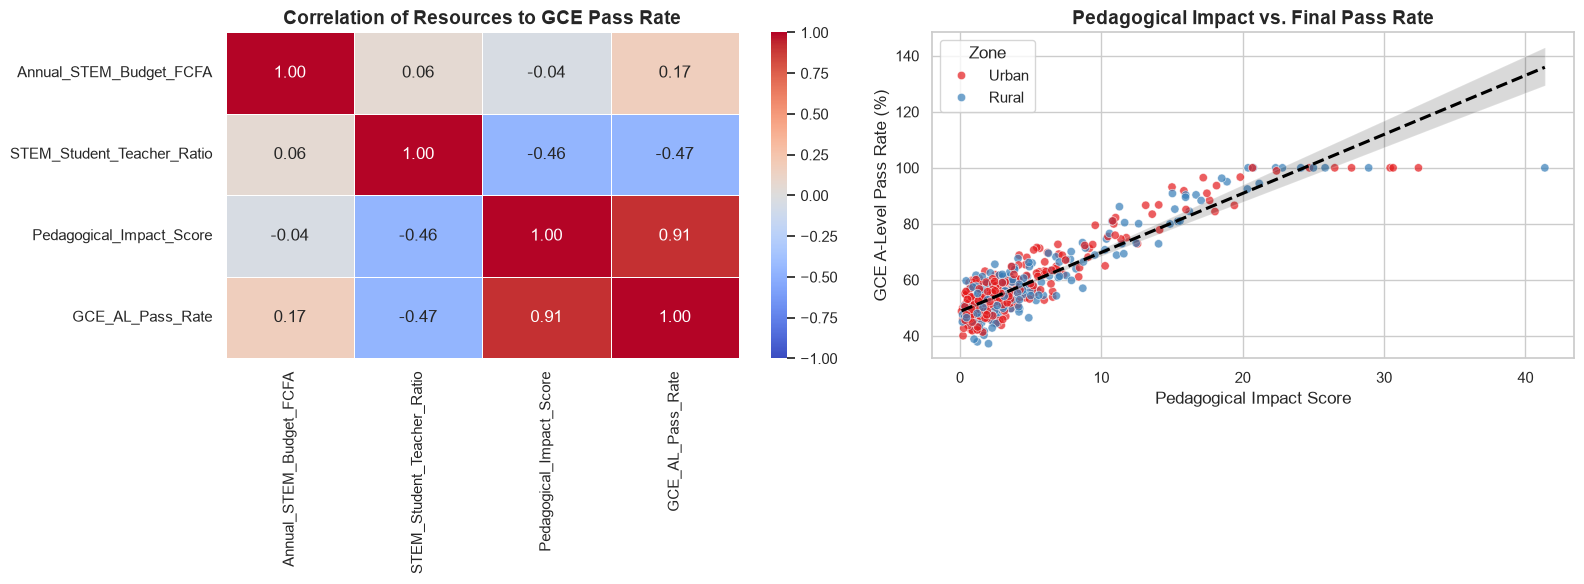

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns


# PART E: DATA VISUALIZATION


# Set a professional visual theme
sns.set_theme(style="whitegrid")

# Create a figure to hold two charts side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


# CHART 1: The Correlation Heatmap

# Select only the crucial numerical columns
numerical_cols = [
    'Annual_STEM_Budget_FCFA', 
    'STEM_Student_Teacher_Ratio', 
    'Pedagogical_Impact_Score', 
    'GCE_AL_Pass_Rate'
]
corr_matrix = df[numerical_cols].corr()

# Plot the heatmap
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", 
    linewidths=0.5, vmin=-1, vmax=1, ax=axes[0]
)
axes[0].set_title("Correlation of Resources to GCE Pass Rate", fontsize=14, fontweight='bold')


# CHART 2: Scatter Plot with Regression Trendline

# Plot the individual schools, colored by Zone
sns.scatterplot(
    data=df, x='Pedagogical_Impact_Score', y='GCE_AL_Pass_Rate', 
    hue='Zone', alpha=0.7, palette="Set1", ax=axes[1]
)

# Add a black mathematical trendline (Linear Regression)
sns.regplot(
    data=df, x='Pedagogical_Impact_Score', y='GCE_AL_Pass_Rate', 
    scatter=False, color="black", line_kws={"linestyle": "--"}, ax=axes[1]
)

axes[1].set_title("Pedagogical Impact vs. Final Pass Rate", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Pedagogical Impact Score")
axes[1].set_ylabel("GCE A-Level Pass Rate (%)")

# Adjust layout and render
plt.tight_layout()
plt.show()